# Link Surrogate Evaluation

Compare 5,000 samples from the trained link MDN with one held-out SeQUeNCe distribution. Wasserstein distance reports the average distribution displacement in milliseconds. The two-sample KS statistic reports the largest difference between the empirical CDFs.

In [38]:
from pathlib import Path
from time import perf_counter

import h5py
import matplotlib.pyplot as plt
import numpy as np
import torch
from scipy.stats import ks_2samp, wasserstein_distance

from train_surrogate_link import FEATURE_NAMES, TIME_PATH, load_model, resolve_device, sample_from_model

MODEL_PATH = None
TEST_DIRECTORY = Path("link/testing/h5")
TEST_FILE_INDEX = 2
SAMPLE_COUNT = 5000
SEED = 7

In [39]:
model_paths = sorted(Path("models").glob("*.pt"))
if MODEL_PATH is None:
    if len(model_paths) != 1:
        raise ValueError(f"Set MODEL_PATH explicitly; found {len(model_paths)} model files")
    MODEL_PATH = model_paths[0]

test_paths = sorted(TEST_DIRECTORY.glob("*.h5"))
if not test_paths:
    raise FileNotFoundError(f"No HDF5 files found under {TEST_DIRECTORY}")
if not 0 <= TEST_FILE_INDEX < len(test_paths):
    raise IndexError(f"TEST_FILE_INDEX must be between 0 and {len(test_paths) - 1}")

device = resolve_device("cuda" if torch.cuda.is_available() else "cpu")
artifact = load_model(MODEL_PATH, device)
test_path = test_paths[TEST_FILE_INDEX]
print(f"Model: {MODEL_PATH}")
print(f"Testing file {TEST_FILE_INDEX + 1}/{len(test_paths)}: {test_path}")
print(f"Device: {device}")

Model: models/surrogate_mdn_validation_nll=-0.7622559287.pt
Testing file 3/80: link/testing/h5/linear_2_ld=10000_me=0.55_de=0.91_a=0.00033_cdn=0.025.h5
Device: cpu


In [40]:
with h5py.File(test_path, "r") as h5_file:
    attributes = h5_file["qnet/metadata/user_optional"].attrs
    parameters = {name: float(attributes[name]) for name in FEATURE_NAMES}
    ground_truth = np.asarray(h5_file[TIME_PATH][:], dtype=np.float32)

sample_start = perf_counter()
surrogate = sample_from_model(artifact, parameters, SAMPLE_COUNT, SEED, device)
sample_elapsed_seconds = perf_counter() - sample_start
wasserstein_ms = wasserstein_distance(ground_truth, surrogate)
normalized_wasserstein = wasserstein_ms / float(np.mean(ground_truth))
ks_result = ks_2samp(ground_truth, surrogate)
ks_statistic = float(ks_result.statistic)
ks_pvalue = float(ks_result.pvalue)

print("Parameters:")
for name, value in parameters.items():
    print(f"  {name}: {value:g}")
print(f"SeQUeNCe samples: {ground_truth.size}")
print(f"Surrogate samples: {surrogate.size}")
print(f"Surrogate generation time: {sample_elapsed_seconds:.6f} seconds")
print(f"Wasserstein distance: {wasserstein_ms:.6f} ms")
print(f"Normalized Wasserstein distance: {normalized_wasserstein:.2%} of the SeQUeNCe mean")
print(f"KS statistic: {ks_statistic:.6f}")
print(f"KS p-value: {ks_pvalue:.6g}")

Parameters:
  link_distance: 10000
  memory_efficiency: 0.55
  detector_efficiency: 0.91
  attenuation: 0.00033
  classical_delay_node: 0.025
SeQUeNCe samples: 5000
Surrogate samples: 5000
Surrogate generation time: 0.082710 seconds
Wasserstein distance: 0.173730 ms
Normalized Wasserstein distance: 3.36% of the SeQUeNCe mean
KS statistic: 0.052000
KS p-value: 2.6749e-06


In [41]:
def summarize(samples):
    """Return summary statistics and selected percentiles."""
    percentiles = list(range(10, 100, 10)) + [95, 99]
    summary = {"mean": np.mean(samples), "std": np.std(samples)}
    for percentile in percentiles:
        summary[f"{percentile}%"] = np.percentile(samples, percentile)
    return summary

ground_truth_summary = summarize(ground_truth)
surrogate_summary = summarize(surrogate)
print(f"{'Metric':<10}{'SeQUeNCe':>16}{'Surrogate':>16}")
for metric in ground_truth_summary:
    print(f"{metric:<10}{ground_truth_summary[metric]:16.6f}{surrogate_summary[metric]:16.6f}")

Metric            SeQUeNCe       Surrogate
mean              5.167222        5.186073
std               5.022326        4.815658
10%               0.600012        0.895627
20%               1.200037        1.495792
30%               1.800063        1.811475
40%               2.700100        2.859498
50%               3.600137        3.656944
60%               4.800188        4.709923
70%               6.300250        6.200504
80%               8.400337        8.453032
90%              11.700475       11.918497
95%              14.700600       15.076552
99%              23.103951       21.199923


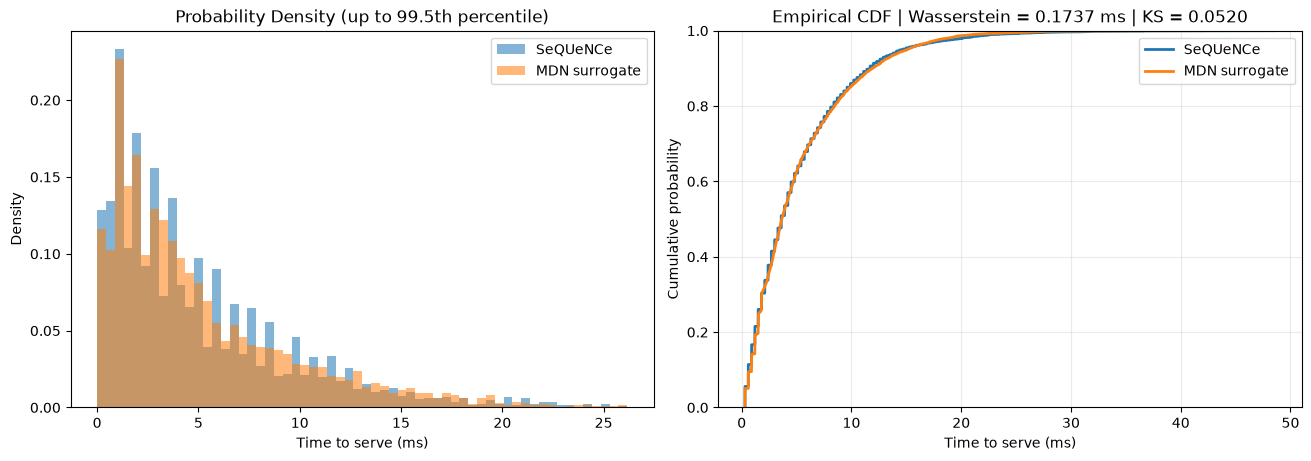

In [42]:
combined = np.concatenate((ground_truth, surrogate))
histogram_limit = float(np.quantile(combined, 0.995))
ground_truth_sorted = np.sort(ground_truth)
surrogate_sorted = np.sort(surrogate)
ground_truth_ecdf = np.arange(1, ground_truth.size + 1) / ground_truth.size
surrogate_ecdf = np.arange(1, surrogate.size + 1) / surrogate.size

figure, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
axes[0].hist(ground_truth, bins=60, range=(0, histogram_limit), density=True, alpha=0.55, label="SeQUeNCe")
axes[0].hist(surrogate, bins=60, range=(0, histogram_limit), density=True, alpha=0.55, label="MDN surrogate")
axes[0].set_title("Probability Density (up to 99.5th percentile)")
axes[0].set_xlabel("Time to serve (ms)")
axes[0].set_ylabel("Density")
axes[0].legend()

axes[1].plot(ground_truth_sorted, ground_truth_ecdf, linewidth=2, label="SeQUeNCe")
axes[1].plot(surrogate_sorted, surrogate_ecdf, linewidth=2, label="MDN surrogate")
axes[1].set_title(f"Empirical CDF | Wasserstein = {wasserstein_ms:.4f} ms | KS = {ks_statistic:.4f}")
axes[1].set_xlabel("Time to serve (ms)")
axes[1].set_ylabel("Cumulative probability")
axes[1].set_ylim(0, 1)
axes[1].grid(alpha=0.25)
axes[1].legend()
plt.show()

Change `TEST_FILE_INDEX` in the configuration cell and rerun the notebook to evaluate another testing condition. Set `MODEL_PATH = Path("models/model_name.pt")` when the directory contains multiple trained models.